<div align="center"><img src="https://github.com/user-attachments/assets/5d3a38ab-b20c-4103-b401-cddc112bfac8" width="300" alt="NOVA IMS Logo">

  <br>
  <br>
  <b>Master in Data Science and Advanced Analytics</b>

  <b>Computational Intelligence for Optimization </b>

  2025–2026

  <h1><b> Vermeer’s <i>Girl with a pearl earing</i>: 100 triangles Challenge <b></h1>
</div>



### <span style="color:#89AC76;">C22_Natural_Selection | Members</span>

<table>
  <thead style="color:#89AC76;">
    <tr>
      <th>Name</th>
      <th>Student ID</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Afonso Hermenegildo</td>
      <td>20221958</td>
    </tr>
    <tr>
      <td>André Ferreira</td>
      <td>20250398</td>
    </tr>
    <tr>
      <td>Marco Martins</td>
      <td>20221951</td>
    </tr>
    <tr>
      <td>Maria Francisca Gonçalves</td>
      <td>20221942</td>
    </tr>
  </tbody>
</table>

## <span style="color:#89AC76;">Table of Contents</span>


[ADICIONAR!!]

---
<h2 id="chapter1" style="color:#89AC76;">1. Imports</h2>
<p><a href="#toc" style="color:#89AC76;"> Back to Table of Contents</a></p>

All libraries used throughout the notebook are imported here. We rely on `Pillow` and `numpy` for image handling, `matplotlib` for visualisation, and `scipy` for statistical testing. The class-provided `library` module is also imported to access the base `Solution` class.

In [1]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), "scripts"))

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from functools import partial #pass a pre-applied selector via functools.partial.
from copy import deepcopy

from scripts.triangle_sol import TriangleSolution, AdaptiveMutationRateTriangleSolution
from scripts.ga import genetic_algorithm
from scripts.ga__2 import genetic_algorithm_vermeer
from scripts.ga_utils import get_fitness
from scripts.experiments import plot_fitness_history
from operators import (
    # selection
    roulette_wheel_selection,
    rank_based_selection,
    tournament_selection,
    # crossover
    one_point_crossover,
    two_point_crossover,
    uniform_crossover,
    geometric_crossover,
    # mutation
    triangle_gaussian_mutation,
    triangle_gaussian_color_mutation,
    triangle_gaussian_vertex_mutation,
    triangle_reset_gene_mutation,
    triangle_reset_mutation,
    triangle_layer_swap_mutation,
    # fitness sharing
    representation_vectors,
    sharing_function,
    compute_counts,
    apply_fitness_sharing, 
    fitness_sharing_selection, 
    measure_diversity,
)
from scripts.statistical_comparison import (
    run_ga_statistical_comparison,
    plot_statistical_comparison,
    run_statistical_test,
    save_statistical_results,
    load_statistical_results,
    plot_statistical_comparison_interactive
)

---
<h2 id="chapter2" style="color:#89AC76;">2. Target Image Loading &amp; Inspection</h2>
<p><a href="#toc" style="color:#89AC76;"> Back to Table of Contents</a></p>

We load the 300×400 target image and convert it to a NumPy array. Keeping the array in memory as a global constant avoids redundant I/O during fitness evaluations, which are called thousands of times per run.

Image size  : 300 x 400 px
Array shape : (400, 300, 4)


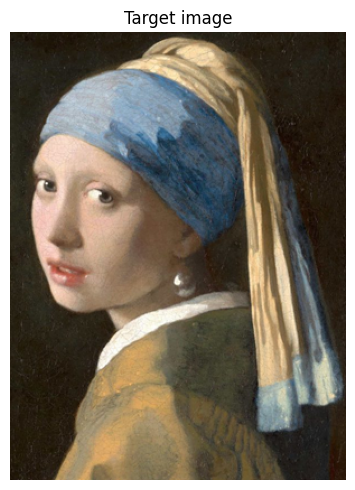

In [2]:
IMG_PATH = "project_info/girl_pearl_earing.png"

target_img = Image.open(IMG_PATH).convert("RGBA")
target_arr = np.array(target_img, dtype=np.float32)

IMG_WIDTH, IMG_HEIGHT = target_img.size   # (width, height) from PIL

print(f"Image size  : {IMG_WIDTH} x {IMG_HEIGHT} px")
print(f"Array shape : {target_arr.shape}")

# Wire the target into TriangleSolution so every instance uses it automatically
TriangleSolution.target_array = target_arr
TriangleSolution.__init__.__defaults__  # sanity-check defaults still present

plt.figure(figsize=(4, 5))
plt.imshow(target_arr / 255)
plt.title("Target image")
plt.axis("off")
plt.tight_layout()
plt.show()

Now, we will check the distribution of our data.

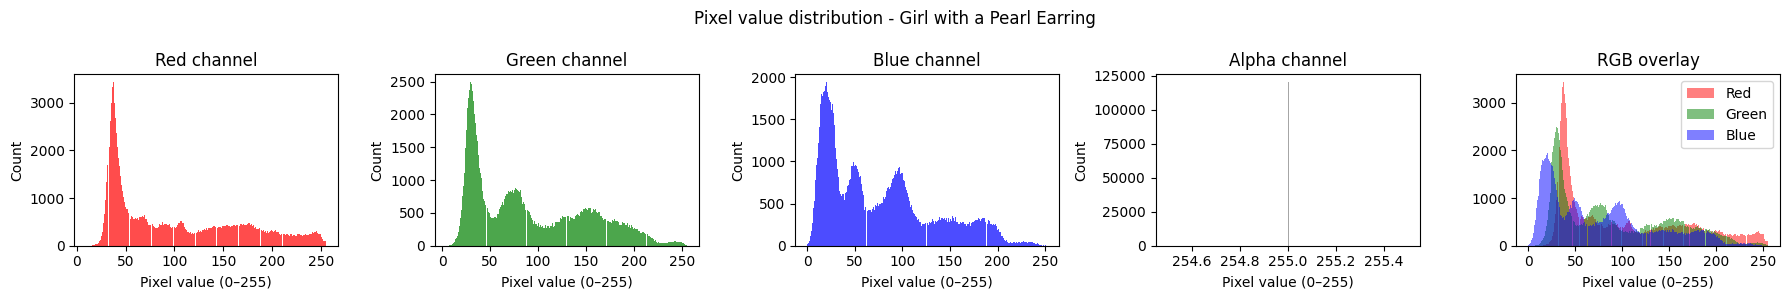

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3))
channels = ['Red', 'Green', 'Blue', 'Alpha']
colors   = ['red', 'green', 'blue', 'gray']

for i, (ch, col) in enumerate(zip(channels, colors)):
    axes[i].hist(target_arr[:, :, i].ravel(), bins=256, color=col, alpha=0.7)
    axes[i].set_title(f'{ch} channel')
    axes[i].set_xlabel('Pixel value (0–255)')
    axes[i].set_ylabel('Count')

# combined RGB only (alpha separate makes the overlay hard to read)
for i, (col, label) in enumerate(zip(['red','green','blue'], ['Red','Green','Blue'])):
    axes[4].hist(target_arr[:, :, i].ravel(), bins=256, color=col, alpha=0.5, label=label)
axes[4].set_title('RGB overlay')
axes[4].set_xlabel('Pixel value (0–255)')
axes[4].legend()

plt.suptitle('Pixel value distribution - Girl with a Pearl Earring')
plt.tight_layout()
plt.show()

---
<h2 id="chapter3" style="color:#89AC76;">3. Solution Representation</h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

### Representation - How the solution is encoded

Each individual in the population encodes a candidate image as an ordered sequence of **100 triangles**, drawn sequentially onto a 300×400 canvas — later triangles occlude earlier ones. Each triangle is represented by **10 real-valued genes**.

```
[ x1, y1, x2, y2, x3, y3, Red, Green, Blue, Alpha]
```


| Gene(s) | Variable | Domain |
|---|---|---|
| x₁, y₁, x₂, y₂, x₃, y₃ | Vertex coordinates | [0, 1] (normalised) |
| R, G, B | Fill colour | [0, 255] |
| A | Opacity | [0, 255] |

### Fitness - measurement of quality of the solution
Fitness is the **pixel-wise RMSE** between the rendered image and the target (lower is  better, since this is a minimisation problem):

$$\text{RMSE} = \sqrt{\frac{1}{W \cdot H \cdot 4} \sum_{i,j,c} (\hat{I}_{ijc} - I_{ijc})^2}$$

where $W=300$, $H=400$, and $C=4$ (RGBA channels)


<span style="color:#BA8E23;">

**TEXT ABOVE INSPIRED IN PRATICAL CLASS 3**

</span>

In [4]:
sol = TriangleSolution()

In [5]:
sol = TriangleSolution()
sol.representation

array([229., 371.,  92., 347., 115., 297., 126.,  94., 218., 250., 101.,
        51.,   7.,  21., 201., 254., 123.,  38., 165., 226.,  86., 262.,
        96.,  29., 132.,  49.,  30.,  63., 198.,  95., 128., 386., 241.,
       389.,  18., 108., 148., 144., 223., 194., 276., 214.,  77.,  78.,
       149., 145.,   7., 244.,  74.,  81., 132., 230., 141., 222.,  51.,
       167., 101.,  55.,  64.,  91.,  44., 323., 270., 360.,  95., 112.,
       240.,  75., 182.,  94., 176., 153., 241., 177., 294., 319., 157.,
       213., 205., 198., 229., 130., 214.,  60., 118.,  66., 133.,  57.,
       196.,  14.,  18.,  59., 211., 244.,  25., 163.,  89.,  77.,  92.,
        84., 125., 264.,  98., 125.,  43.,  70., 169.,  92., 182., 174.,
        89., 101.,  16., 152.,  48.,  37., 164.,   8., 197.,   8.,  45.,
       386., 119., 279.,   6., 240., 139., 163.,  95., 228., 115., 245.,
       215., 149., 158.,  22.,   9., 105.,  86., 110., 251., 232., 212.,
       348.,  76., 358.,  43., 245., 150.,  27.,  6

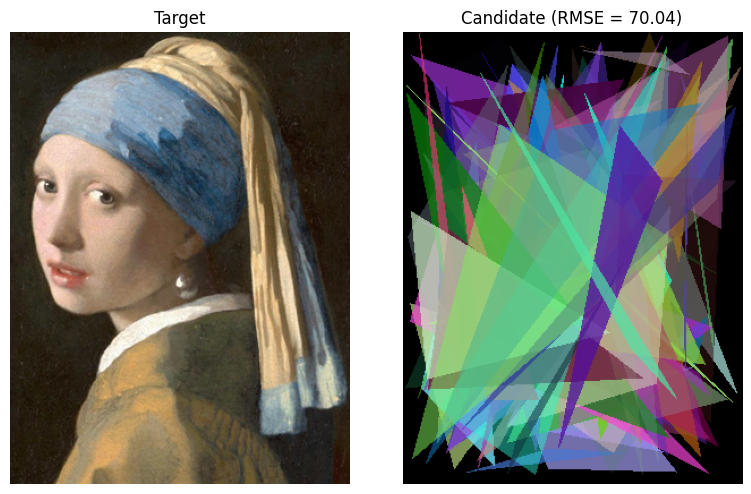

In [6]:
sol.show()

The output generated is a **single random individual**.

<h2 id="chapter4" style="color:#89AC76;">4. Baseline GA Run</h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

A single run with sensible defaults to confirm everything works end-to-end.

## test 1

In [24]:
# 1. Criar um wrapper inteligente para injetar o apply_fitness_sharing automaticamente
class AutomaticFitnessSharingSelection:
    def __init__(self, sigma_share=50.0, alpha=1.0, tournament_size=3):
        self.sigma_share = sigma_share
        self.alpha = alpha
        self.tournament_size = tournament_size
        self.last_pop_id = None

    def __call__(self, population):
        # Se for uma nova geração, a lista 'population' terá um ID na memória diferente
        if id(population) != self.last_pop_id:
            # Calcula as penalizações de partilha e guarda em ind._shared_fitness de forma vetorizada
            apply_fitness_sharing(population, sigma_share=self.sigma_share, alpha=self.alpha)
            self.last_pop_id = id(population)
        
        # Chama a seleção real que agora vai ler o _shared_fitness guardado
        return fitness_sharing_selection(
            population, 
            method="tournament", 
            sigma_share=self.sigma_share, 
            alpha=self.alpha, 
            tournament_size=self.tournament_size
        )

In [19]:
# 2. Configurar os parâmetros corretos
SHARING_PARAMS = dict(
    population_size=800,  # 500 está ótimo se o fitness sharing funcionar a sério
    n_generations=1000,
    
    # ATUALIZADO: Agora usa o nosso wrapper automático e inteligente
    selection_function=AutomaticFitnessSharingSelection(
        sigma_share=80.0,   # Se a diversidade continuar baixa, aumenta para 80-100
        alpha=1.0,
        tournament_size=4
    ),
    
    crossover_function=one_point_crossover,
    mutation_function=partial(
        triangle_gaussian_mutation,
        sigma_vertex=15,    # Reduzir ligeiramente ajuda a refinar no fim
        sigma_colour=15
    ),
    
    crossover_rate=0.9,
    mutation_rate=0.03,     # Subir ligeiramente a mutação ajuda a quebrar o gelo
    mutation_rate_decay=0.001, # Adicionar um decaimento ligeiro ajuda a estabilizar nas últimas gerações
    
    elitism_n=4, # Subir o elitismo proporcionalmente para proteger os melhores de cada nicho
    n_jobs=-1,
    verbose=True,
    verbose_every=25,
)

# Execução do algoritmo com Fitness Sharing REAL ativo
best_sol, history, avg_history = genetic_algorithm(**SHARING_PARAMS)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 57.8694 | avg RMSE: 69.0633 | mut rate: 0.03000
Gen   25 | best RMSE: 42.4182 | avg RMSE: 44.9294 | mut rate: 0.02926
Gen   50 | best RMSE: 37.7719 | avg RMSE: 38.7442 | mut rate: 0.02854
Gen   75 | best RMSE: 34.8276 | avg RMSE: 35.6482 | mut rate: 0.02783
Gen  100 | best RMSE: 32.8646 | avg RMSE: 33.5798 | mut rate: 0.02715
Gen  125 | best RMSE: 31.3283 | avg RMSE: 32.0146 | mut rate: 0.02648
Gen  150 | best RMSE: 30.3408 | avg RMSE: 30.9456 | mut rate: 0.02582
Gen  175 | best RMSE: 29.0977 | avg RMSE: 29.8400 | mut rate: 0.02519
Gen  200 | best RMSE: 28.2999 | avg RMSE: 28.8681 | mut rate: 0.02456
Gen  225 | best RMSE: 27.8842 | avg RMSE: 28.4270 | mut rate: 0.02396
Gen  250 | best RMSE: 27.4933 | avg RMSE: 27.9458 | mut rate: 0.02337
Gen  275 | best RMSE: 27.1667 | avg RMSE: 27.6867 | mut rate: 0.02279
Gen  300 | best RMSE: 26.8986 | avg RMSE: 27.4405 | mut rate: 0.02223
Gen  325 | best RMSE: 26.6759 | avg RMSE: 27.1339 | mut rate: 0.02168
Gen  350 | best RMSE

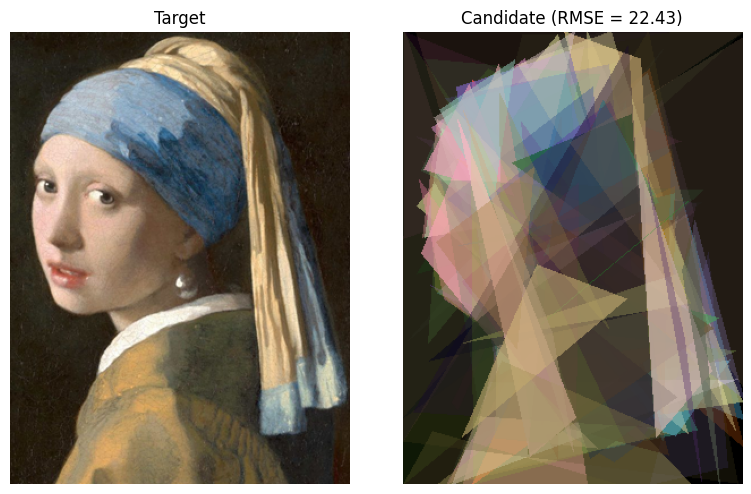

In [20]:
best_sol.show()

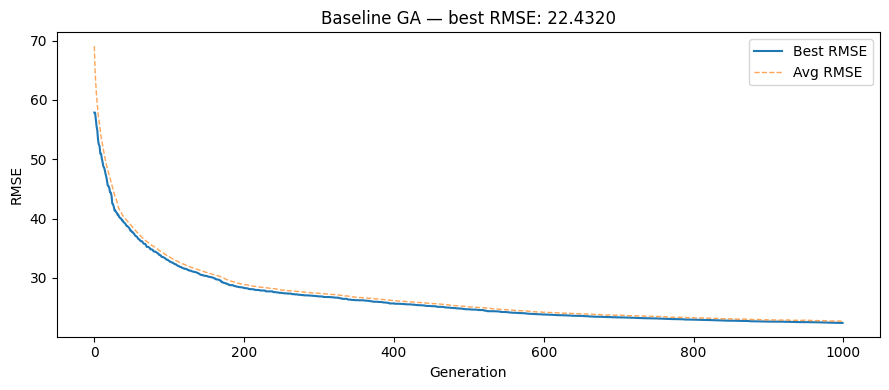

In [35]:
plot_fitness_history(
    history,
    avg_history,
    title=f"Baseline GA — best RMSE: {history[-1]:.4f}",
)

## test 2

In [ ]:
class AdvancedFitnessSharingSelection:
    def __init__(self, sigma_share=0.15, alpha=1.0, tournament_size=5):
        # pencentual sigma_share (ex: 0.15 = 15% de distância máxima no espaço normalizado)
        self.sigma_share = sigma_share
        self.alpha = alpha
        self.tournament_size = tournament_size
        self.last_pop_id = None

    def _apply_normalized_sharing(self, population):
        """Calcula o fitness sharing normalizando os eixos para evitar a distorção vértices vs cores."""
        N = len(population)
        # 1. Extract representations (N, D)
        vecs = np.stack([ind.representation.flatten().astype(np.float64) for ind in population])
        
        # 2. Normalizes scales 
        # Cada bloco de 10 genes: [x1, y1, x2, y2, x3, y3, R, G, B, A]
        norm_mask = np.tile([300.0, 400.0, 300.0, 400.0, 300.0, 400.0, 255.0, 255.0, 255.0, 255.0], vecs.shape[1] // 10)
        vecs_normalized = vecs / norm_mask

        # 3. Calculates distances between pairs in a normalized space [0, 1]
        diff = vecs_normalized[:, np.newaxis, :] - vecs_normalized[np.newaxis, :, :]
        dists = np.sqrt((diff ** 2).sum(axis=2))
        
        # Maximum theoretical distance possible in a normalized space of D dimension
        max_theoretical_dist = np.sqrt(vecs.shape[1])
        effective_sigma = self.sigma_share * max_theoretical_dist

        # 4. Calculationss
        sh = np.where(dists < effective_sigma, 1.0 - (dists / effective_sigma) ** self.alpha, 0.0)
        counts = sh.sum(axis=1)

        # 5. Aplies penalization to RMSE
        for ind, nc in zip(population, counts):
            ind._shared_fitness = get_fitness(ind) * nc

    def __call__(self, population):
        if id(population) != self.last_pop_id:
            self._apply_normalized_sharing(population)
            self.last_pop_id = id(population)
        
        return fitness_sharing_selection(
            population, 
            method="tournament", 
            sigma_share=self.sigma_share, 
            alpha=self.alpha, 
            tournament_size=self.tournament_size
        )

In [31]:
VERMEER_SUPER_PARAMS = dict(
    population_size=800,  
    n_generations=1000,
    
    # Advanced selection with normalized distances
    selection_function=AdvancedFitnessSharingSelection(
        sigma_share=0.15, # 15% de raio de nicho no espaço normalizado
        alpha=1.0,
        tournament_size=4  # High selective pressure
    ),
    
    # test with Uniform Crossover (altamente recomendado para este problema)
    crossover_function=partial(uniform_crossover, swap_prob=0.5),
    
    # Mutation
    mutation_function=partial(
        triangle_gaussian_mutation,
        sigma_vertex=25,       # Passos largos para acertar na silhueta
        sigma_colour=20
    ),
    
    # Activation of mutatioon in layers (avoids "blind" sobreposition triangles)
    structural_mutation_function=triangle_layer_swap_mutation,
    structural_mutation_rate=0.15, # 15% de chance de reorganizar as fatias
    
    crossover_rate=0.85,
    mutation_rate=0.035,        
    mutation_rate_decay=0.001, 
    
    elitism_n=4,
    n_jobs=-1,
    verbose=True,
    verbose_every=25,
)


best_sharing, hist_sharing, avg_hist_sharing = genetic_algorithm_vermeer(**VERMEER_SUPER_PARAMS)

print("-" * 40)
print(f"Best RMSE with Vermeer Engine: {get_fitness(best_sharing):.4f}")

Gen    0 | Best RMSE: 57.2311 | Avg RMSE: 68.8506 | Mut Rate: 0.03500
Gen   25 | Best RMSE: 40.2588 | Avg RMSE: 42.6558 | Mut Rate: 0.03414
Gen   50 | Best RMSE: 33.4696 | Avg RMSE: 35.2875 | Mut Rate: 0.03329
Gen   75 | Best RMSE: 30.0804 | Avg RMSE: 31.6349 | Mut Rate: 0.03247
Gen  100 | Best RMSE: 28.2496 | Avg RMSE: 29.6409 | Mut Rate: 0.03167
Gen  125 | Best RMSE: 27.7490 | Avg RMSE: 28.9655 | Mut Rate: 0.03089
Gen  150 | Best RMSE: 27.4971 | Avg RMSE: 28.7609 | Mut Rate: 0.03013
Gen  175 | Best RMSE: 26.9056 | Avg RMSE: 28.2018 | Mut Rate: 0.02938
Gen  200 | Best RMSE: 26.5114 | Avg RMSE: 27.8136 | Mut Rate: 0.02866
Gen  225 | Best RMSE: 26.2597 | Avg RMSE: 27.4709 | Mut Rate: 0.02795
Gen  250 | Best RMSE: 26.0477 | Avg RMSE: 27.3703 | Mut Rate: 0.02726
Gen  275 | Best RMSE: 25.9123 | Avg RMSE: 27.1774 | Mut Rate: 0.02659
Gen  300 | Best RMSE: 25.6218 | Avg RMSE: 26.9803 | Mut Rate: 0.02593
Gen  325 | Best RMSE: 25.6098 | Avg RMSE: 26.8380 | Mut Rate: 0.02529
Gen  350 | Best RMSE

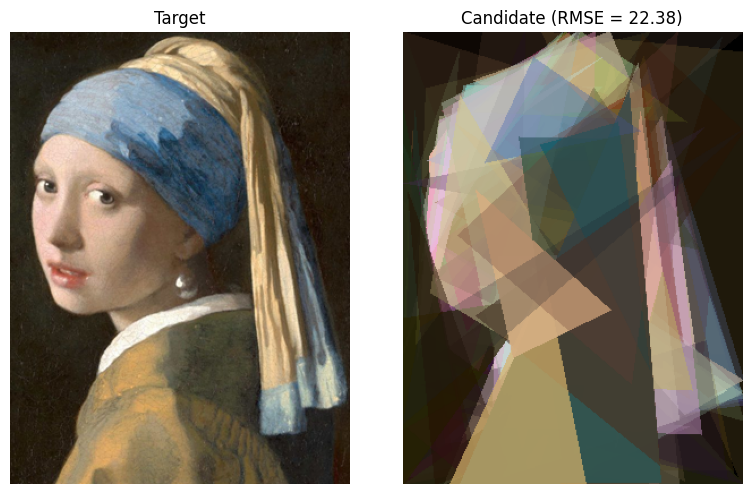

In [32]:
best_sharing.show()

## anterior | pré fitness sharing

In [ ]:
""" ANTERIOR:
BASELINE_PARAMS = dict(
    population_size = 50,
    n_generations = 200,
    selection_function = tournament_selection,
    crossover_function = one_point_crossover,
    mutation_function = triangle_gaussian_mutation,
    crossover_rate = 0.9,
    mutation_rate = 0.02,
    mutation_rate_decay = None,
    elitism_n = 2,
    n_jobs = -1,
    verbose = True,
    verbose_every = 25,
)

best_sol, history, avg_history = genetic_algorithm(**BASELINE_PARAMS)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

"""

Gen    0 | best RMSE: 57.4659 | avg RMSE: 68.1869 | mut rate: 0.02000
Gen   25 | best RMSE: 51.8110 | avg RMSE: 52.2461 | mut rate: 0.02000
Gen   50 | best RMSE: 49.0399 | avg RMSE: 49.3354 | mut rate: 0.02000
Gen   75 | best RMSE: 46.9828 | avg RMSE: 47.3295 | mut rate: 0.02000
Gen  100 | best RMSE: 45.1102 | avg RMSE: 45.4459 | mut rate: 0.02000
Gen  125 | best RMSE: 43.4834 | avg RMSE: 43.7123 | mut rate: 0.02000
Gen  150 | best RMSE: 42.1624 | avg RMSE: 42.3839 | mut rate: 0.02000
Gen  175 | best RMSE: 40.5928 | avg RMSE: 40.9435 | mut rate: 0.02000
Gen  199 | best RMSE: 39.2180 | avg RMSE: 39.5183 | mut rate: 0.02000

Finished. Best RMSE: 39.2180
Best RMSE : 39.2180


<h3 id="chapter4.1" style="color:#89AC76;">4.1 Convergence Plot</h3>

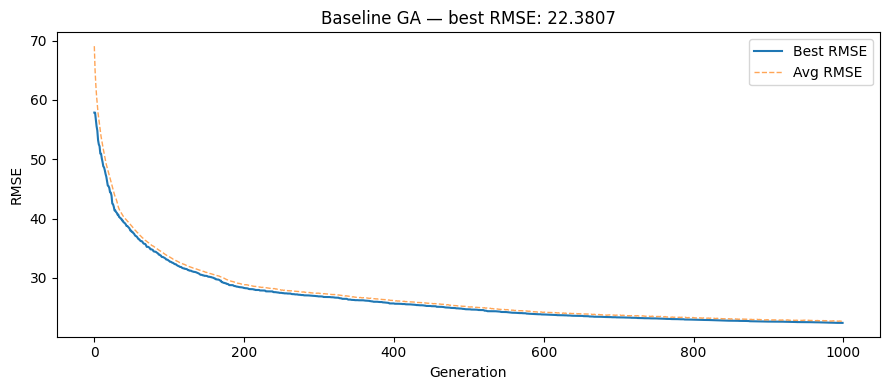

In [34]:
plot_fitness_history(
    history,
    avg_history,
    title=f"Baseline GA — best RMSE: {hist_sharing[-1]:.4f}",
)

<h2 id="chapter5" style="color:#89AC76;">5. Hill Climbing for Local Search </h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

-- ainda não foi testado --- em desenvolvimento

<h2 id="chapter6" style="color:#89AC76;">6. Best Candidate vs. Target </h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

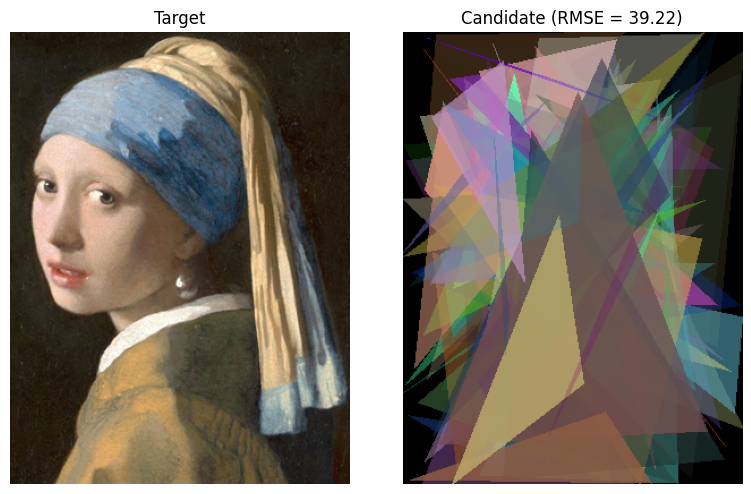

In [8]:
best_sol.show()

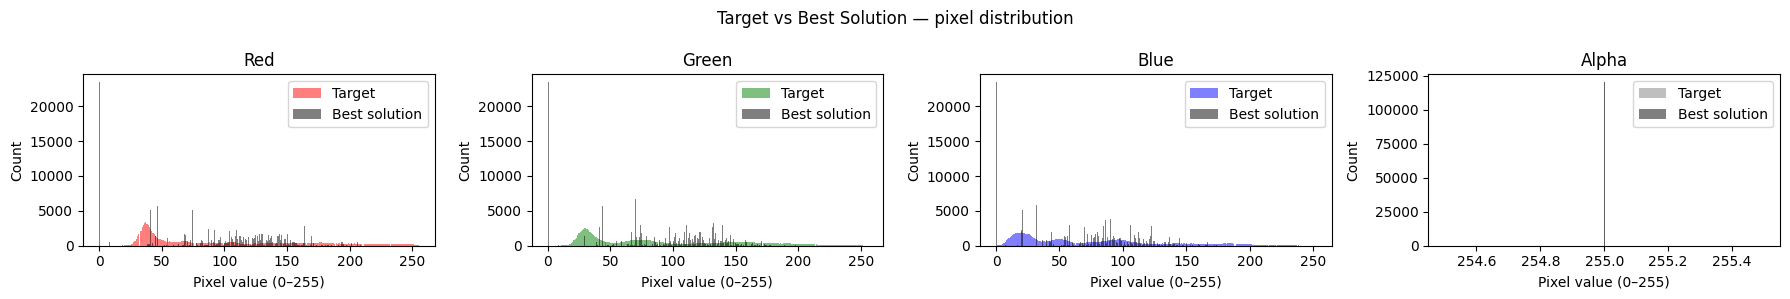

In [ ]:
#### Does this make sense???


rendered_arr = np.array(best_sol.get_image())

fig, axes = plt.subplots(1, 4, figsize=(18, 3))
channels = ['Red', 'Green', 'Blue', 'Alpha']
colors   = ['red', 'green', 'blue', 'gray']

for i, (ch, col) in enumerate(zip(channels, colors)):
    axes[i].hist(target_arr[:,:,i].ravel(),   bins=256, color=col,   alpha=0.5, label='Target')
    axes[i].hist(rendered_arr[:,:,i].ravel(), bins=256, color='black', alpha=0.5, label='Best solution')
    axes[i].set_title(ch)
    axes[i].set_xlabel('Pixel value (0–255)')
    axes[i].set_ylabel('Count')
    axes[i].legend()

plt.suptitle('Target vs Best Solution — pixel distribution')
plt.tight_layout()
plt.show()

<h2 id="chapter4" style="color:#89AC76;">6. Exploring genetic operators</h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

Try multiple genetic operators and do statistical tests to compare them and, if applicable get the best parameters for them.

<h3 id="chapter6.1" style="color:#89AC76;">6.1 Selection</h3>

try here all of the selection operators and do statistical tests to compare between them

to choose the size of the tournament selection, we need to take into account the size of the population and what is the resulting selection pressure, so that we can scale up the size of the population at the final run

In [33]:
selection_statistical_comparison = run_ga_statistical_comparison(
    "selection_function",
    [
        roulette_wheel_selection,
        rank_based_selection,
        tournament_selection, # default tournament size is 2, # with a population of size 200, this is a selection pressure of 1%
        lambda p: tournament_selection(p, tournament_size=3), # with a population of size 200, this is a selection pressure of 1.5%
        lambda p: tournament_selection(p, tournament_size=5), # with a population of size 200, this is a selection pressure of 2.5%
        lambda p: tournament_selection(p, tournament_size=10), # with a population of size 200, this is a selection pressure of 5%
    ]
)


Starting statistical comparison: 180 GA runs, 36,000 total generations



Progress: 100%|██████████| 36000/36000 [38:17<00:00, 15.67 gen/s]


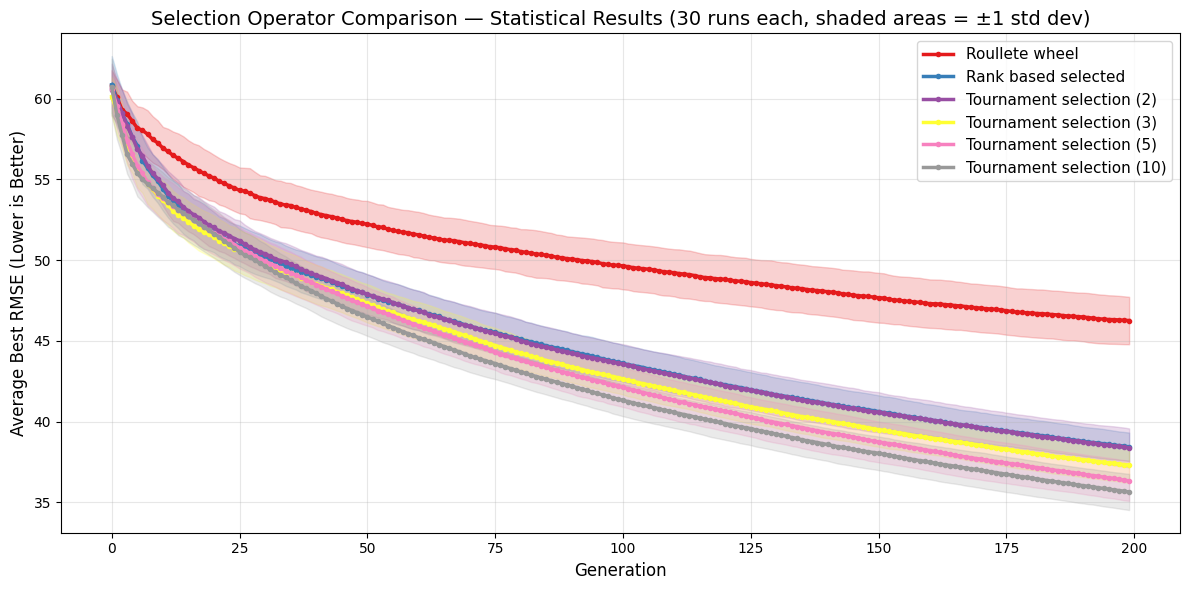

In [34]:
selection_functions = [
    "Roullete wheel",
    "Rank based selected",
    "Tournament selection (2)",
    "Tournament selection (3)",
    "Tournament selection (5)",
    "Tournament selection (10)"
]

plot_statistical_comparison(
    selection_statistical_comparison,
    labels=selection_functions,
    title="Selection Operator Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

based on the results from this statistical comparison, let's try even lower selection pressures in tournament selection

In [10]:
selection_statistical_comparison2 = run_ga_statistical_comparison(
    "selection_function",
    [
        lambda p: tournament_selection(p, tournament_size=10), # with a population of size 200, this is a selection pressure of 5%
        lambda p: tournament_selection(p, tournament_size=15), # with a population of size 200, this is a selection pressure of 7.5%
        lambda p: tournament_selection(p, tournament_size=20), # with a population of size 200, this is a selection pressure of 10%
        lambda p: tournament_selection(p, tournament_size=30), # with a population of size 200, this is a selection pressure of 15%
    ]
)


Starting statistical comparison: 120 GA runs, 24,000 total generations



Progress: 100%|██████████| 24000/24000 [25:55<00:00, 15.42 gen/s]


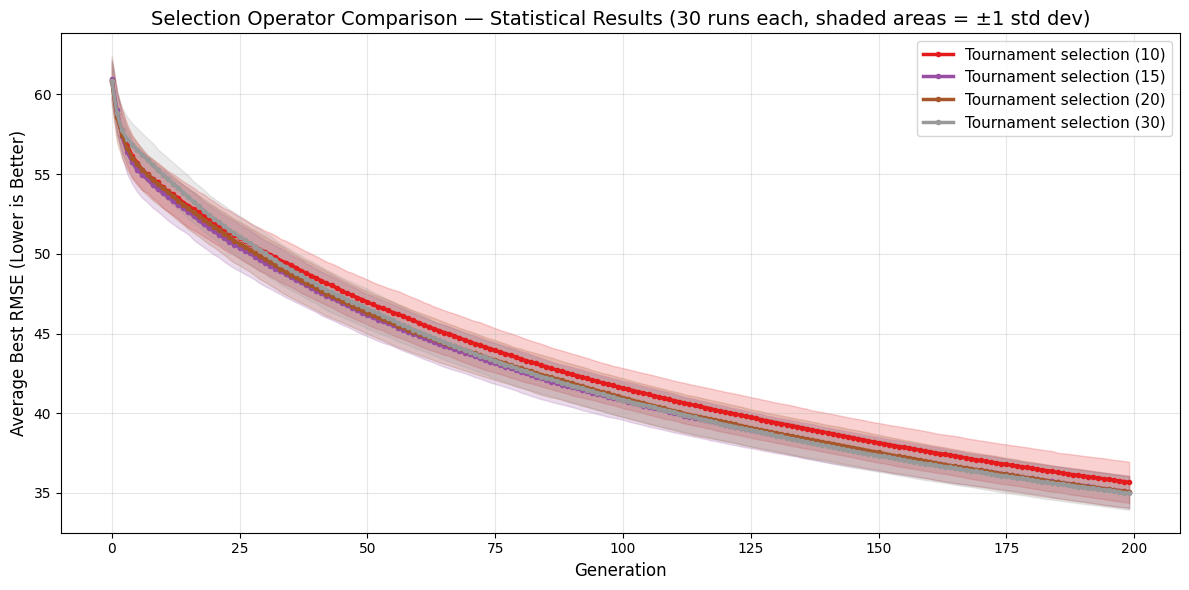

In [11]:
selection_functions = [
    "Tournament selection (10)",
    "Tournament selection (15)",
    "Tournament selection (20)",
    "Tournament selection (30)",
]

plot_statistical_comparison(
    selection_statistical_comparison2,
    labels=selection_functions,
    title="Selection Operator Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

All of the values seem to be statistically equivalent, with all of them being really close together and inside the standard deviations of eachother

we should now do statistical tests to choose the best option

<h3 id="chapter6.2" style="color:#89AC76;">6.2 Crossover</h3>

try here all of the crossover operators and do statistical tests to compare between them

In [3]:
crossover_statistical_comparison = run_ga_statistical_comparison(
    "crossover_function",
    [
        one_point_crossover,
        two_point_crossover,
        uniform_crossover,
        geometric_crossover
    ]
)


Starting statistical comparison: 120 GA runs, 24,000 total generations



Progress: 100%|██████████| 24000/24000 [27:56<00:00, 14.31 gen/s]


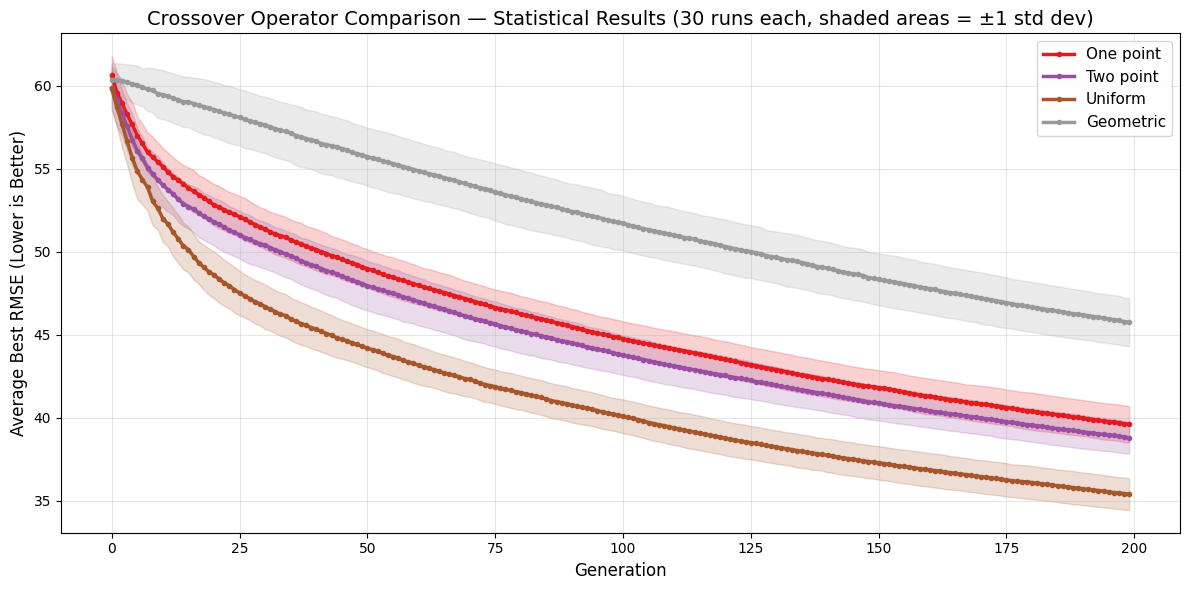

In [4]:
crossover_functions = [
    "One point",
    "Two point",
    "Uniform",
    "Geometric"
]

plot_statistical_comparison(
    crossover_statistical_comparison,
    labels=crossover_functions,
    title="Crossover Operator Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [5]:
run_statistical_test(
    crossover_statistical_comparison[one_point_crossover]["best_per_run"],
    crossover_statistical_comparison[uniform_crossover]["best_per_run"],
    name_a="One point",
    name_b="Uniform",
    paired=False
)

One point normality p-value: 0.5982
Uniform normality p-value: 0.3007

Welch t-test
p-value: 0.0000

One point mean final RMSE: 39.6114
Uniform mean final RMSE: 35.4099
Difference is statistically significant.


In [6]:
run_statistical_test(
    crossover_statistical_comparison[two_point_crossover]["best_per_run"],
    crossover_statistical_comparison[uniform_crossover]["best_per_run"],
    name_a="Two point",
    name_b="Uniform",
    paired=False
)

Two point normality p-value: 0.0644
Uniform normality p-value: 0.3007

Welch t-test
p-value: 0.0000

Two point mean final RMSE: 38.7940
Uniform mean final RMSE: 35.4099
Difference is statistically significant.


<h3 id="chapter6.3" style="color:#89AC76;">6.3 Mutation</h3>

In [ ]:
# mutation_statistical_comparison = run_ga_statistical_comparison(
#     "mutation_function",
#     [
#         triangle_gaussian_mutation,
#         triangle_gaussian_color_mutation,
#         triangle_gaussian_vertex_mutation,
#         triangle_reset_gene_mutation,
#         triangle_reset_mutation,
#         triangle_layer_swap_mutation
#     ]
# )


Starting statistical comparison: 180 GA runs × 200 generations = 36,000 total generations



Progress: 100%|██████████| 180/180 [39:59<00:00, 13.33s/ run]


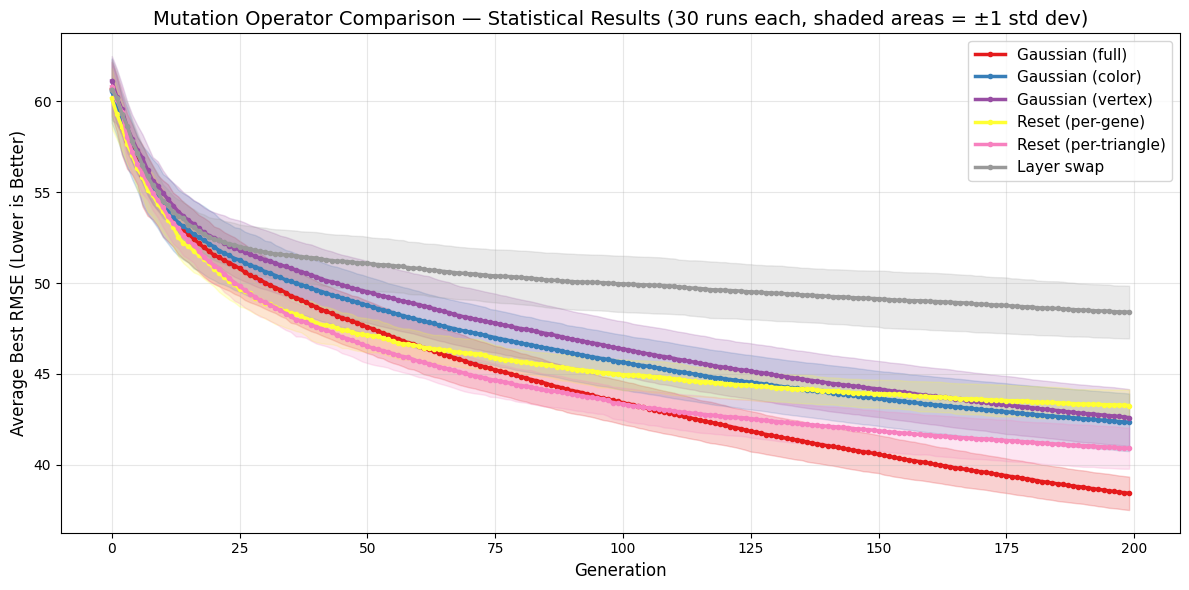

In [ ]:
mutation_modes = [
    "Gaussian (full)",
    "Gaussian (color)",
    "Gaussian (vertex)",
    "Reset (per-gene)",
    "Reset (per-triangle)",
    "Layer swap"
]

plot_statistical_comparison(
    mutation_statistical_comparison,
    labels=mutation_modes,
    title="Mutation Operator Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

Now we need to select the best mutation rate

In [ ]:
# mutation_rate_statistical_comparison = run_ga_statistical_comparison(
#     "mutation_rate",
#     [
#         0.50,
#         0.20,
#         0.10,
#         0.05,
#         0.02,
#         0.01
#     ]
# )


Starting statistical comparison: 180 GA runs, 36,000 total generations



Progress: 100%|██████████| 36000/36000 [45:15<00:00, 13.26 gen/s] 


In [ ]:
# save_statistical_results(
#     mutation_rate_statistical_comparison,
#     "results/mutation_rate_statistical_comparison.pkl"
# )

In [3]:
mutation_rate_statistical_comparison = load_statistical_results("results/mutation_rate_statistical_comparison.pkl")

In [7]:
mutation_rates = [
    "0.50",
    "0.20",
    "0.10",
    "0.05",
    "0.02",
    "0.01"
]

plot_statistical_comparison_interactive(
    mutation_rate_statistical_comparison,
    labels=mutation_rates,
    title="Mutation Rate Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [9]:
run_statistical_test(
    mutation_rate_statistical_comparison[0.01]["best_per_run"],
    mutation_rate_statistical_comparison[0.02]["best_per_run"],
    name_a="0.01",
    name_b="0.02",
    paired=False
)

0.01 normality p-value: 0.2514
0.02 normality p-value: 0.4021

Welch t-test
p-value: 0.0013

0.01 mean final RMSE: 40.2189
0.02 mean final RMSE: 39.0638
Difference is statistically significant.


In [11]:
run_statistical_test(
    mutation_rate_statistical_comparison[0.02]["best_per_run"],
    mutation_rate_statistical_comparison[0.05]["best_per_run"],
    name_a="0.02",
    name_b="0.05",
    paired=False
)

0.02 normality p-value: 0.4021
0.05 normality p-value: 0.9225

Welch t-test
p-value: 0.0000

0.02 mean final RMSE: 39.0638
0.05 mean final RMSE: 37.0871
Difference is statistically significant.


In [22]:
run_statistical_test(
    mutation_rate_statistical_comparison[0.05]["best_per_run"],
    mutation_rate_statistical_comparison[0.10]["best_per_run"],
    name_a="0.05",
    name_b="0.10",
    paired=False
)

0.05 normality p-value: 0.9225
0.10 normality p-value: 0.0003

Mann-Whitney U / Wilcoxon rank-sum test
p-value: 0.0007

0.05 mean final RMSE: 37.0871
0.10 mean final RMSE: 36.1952
Difference is statistically significant.


### gaussian mutation has two additional parameters we can tune, sigma_vertex and sigma_color

In [ ]:
# sigma_vertex_statistical_comparison = run_ga_statistical_comparison(
#     "sigma_vertex",
#     [
#         2,
#         5,
#         10,
#         20,
#         50
#     ]
# )


Starting statistical comparison: 150 GA runs, 30,000 total generations



Progress: 100%|██████████| 30000/30000 [33:35<00:00, 14.88 gen/s] 


In [ ]:
# save_statistical_results(
#     sigma_vertex_statistical_comparison,
#     "results/sigma_vertex_statistical_comparison.pkl"
# )

In [3]:
sigma_vertex_statistical_comparison = load_statistical_results("results/sigma_vertex_statistical_comparison.pkl")

In [4]:
sigma_vertex = [
    "2",
    "5",
    "10",
    "20",
    "50"
]

plot_statistical_comparison_interactive(
    sigma_vertex_statistical_comparison,
    labels=sigma_vertex,
    title="Mutation Sigma Vertex Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [5]:
run_statistical_test(
    sigma_vertex_statistical_comparison[2]["best_per_run"],
    sigma_vertex_statistical_comparison[5]["best_per_run"],
    "2",
    "5",
    paired=False
)

2 normality p-value: 0.6887
5 normality p-value: 0.8958

Welch t-test
p-value: 0.2730

2 mean final RMSE: 39.0830
5 mean final RMSE: 39.4074
No statistically significant difference detected.


maybe running for more epochs will give us more separation between the values

In [ ]:
# sigma_color_statistical_comparison = run_ga_statistical_comparison(
#     "sigma_color",
#     [
#         2,
#         5,
#         10,
#         20,
#         50
#     ]
# )


Starting statistical comparison: 150 GA runs, 30,000 total generations



Progress: 100%|██████████| 30000/30000 [31:03<00:00, 16.10 gen/s]


In [ ]:
# save_statistical_results(
#     sigma_color_statistical_comparison,
#     "results/sigma_color_statistical_comparison.pkl"
# )

In [6]:
sigma_color_statistical_comparison = load_statistical_results("results/sigma_color_statistical_comparison.pkl")

In [7]:
sigma_color = [
    "2",
    "5",
    "10",
    "20",
    "50"
]

plot_statistical_comparison_interactive(
    sigma_color_statistical_comparison,
    labels=sigma_color,
    title="Mutation Sigma Color Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

all of them seem equivalent

In [10]:
run_statistical_test(
    sigma_color_statistical_comparison[2]["best_per_run"],
    sigma_color_statistical_comparison[10]["best_per_run"],
    "2",
    "10",
    paired=False
)

2 normality p-value: 0.2489
10 normality p-value: 0.2096

Welch t-test
p-value: 0.5744

2 mean final RMSE: 39.0989
10 mean final RMSE: 39.2479
No statistically significant difference detected.


<h3 id="chapter6.3.1" style="color:#89AC76;">6.3.1 Adaptive mutation rate</h3>

Now we will test strategies for adapting mutation rates:
- Mutation rate decay
- Self-adaptive mutation rate (gene)

In [3]:
mutation_rate_decay_statistical_comparison = run_ga_statistical_comparison(
    "mutation_rate_decay",
    [
        None,
        0.1,
        0.01,
        0.001,
        0.0001,
        0.00001
    ]
)


Starting statistical comparison: 180 GA runs, 36,000 total generations



Progress: 100%|██████████| 36000/36000 [38:20<00:00, 15.65 gen/s] 


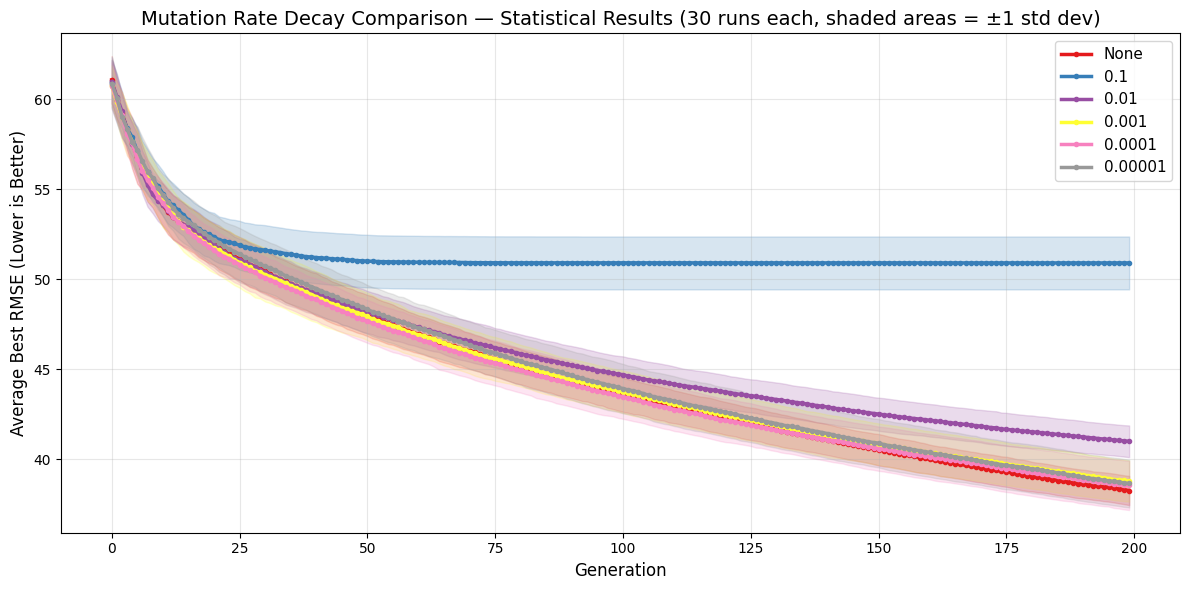

In [4]:
# Visualize mutation statistical results with standard deviation bands
mutation_rate_decay_values = [
    "None",
    "0.1",
    "0.01",
    "0.001",
    "0.0001",
    "0.00001"
]

plot_statistical_comparison(
    mutation_rate_decay_statistical_comparison,
    labels=mutation_rate_decay_values,
    title="Mutation Rate Decay Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [ ]:
adaptive_mutation_rate_statistical_comparison = run_ga_statistical_comparison(
    "solution_class",
    [
        TriangleSolution,
        AdaptiveMutationRateTriangleSolution
    ]
)


Starting statistical comparison: 60 GA runs × 200 generations = 12,000 total generations



Progress: 100%|██████████| 60/60 [06:23<00:00,  6.40s/ run]


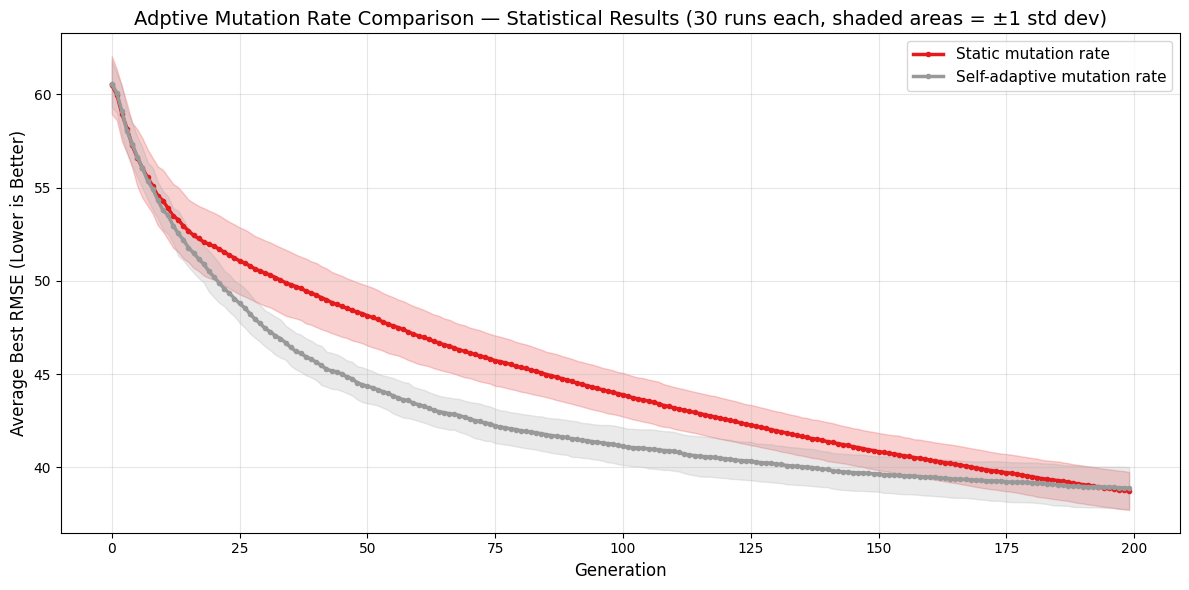

In [7]:
# Visualize mutation statistical results with standard deviation bands
mutation_rate_strategy = [
    "Static mutation rate",
    "Self-adaptive mutation rate"
]

plot_statistical_comparison(
    adaptive_mutation_rate_statistical_comparison,
    labels=mutation_rate_strategy,
    title="Adptive Mutation Rate Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [ ]:
adaptive_mutation_rate_statistical_comparison2 = run_ga_statistical_comparison(
    "solution_class",
    [
        TriangleSolution,
        AdaptiveMutationRateTriangleSolution
    ],
    n_generations=500
)


Starting statistical comparison: 60 GA runs, 30,000 total generations



Progress: 100%|██████████| 30000/30000 [33:49<00:00, 14.78 gen/s]


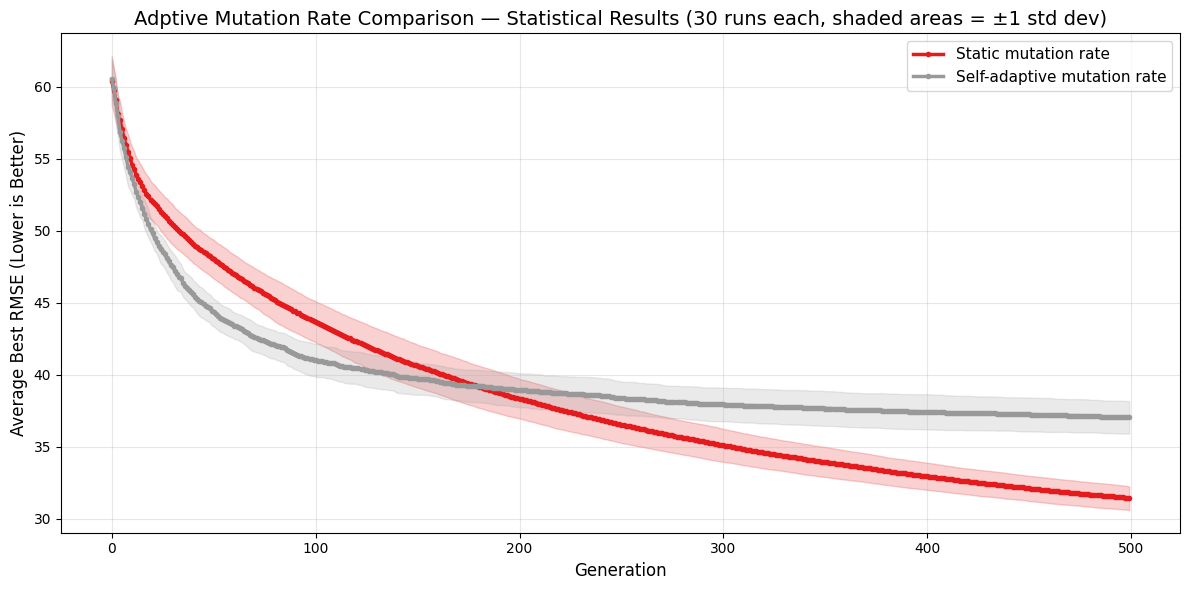

In [5]:
# Visualize mutation statistical results with standard deviation bands
mutation_rate_strategy = [
    "Static mutation rate",
    "Self-adaptive mutation rate"
]

plot_statistical_comparison(
    adaptive_mutation_rate_statistical_comparison2,
    labels=mutation_rate_strategy,
    title="Adptive Mutation Rate Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

run this comparison again with the updated adaptive mutation rate solution

In [3]:
np.random.seed(33)
best_sol, history, avg_history = genetic_algorithm(
    solution_class=AdaptiveMutationRateTriangleSolution,
    population_size=50,
    n_generations=200,
    selection_function=lambda p: tournament_selection(p, tournament_size=10),
    crossover_function=uniform_crossover,
    mutation_function=lambda i, m: triangle_gaussian_mutation(i, m, sigma_mutation_rate=0.01),
    crossover_rate=0.9,
    mutation_rate=0.,
    mutation_rate_decay=None,
    elitism_n=2
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 57.5638 | avg RMSE: 64.0368 | mut rate: 0.01214
Gen   50 | best RMSE: 44.7646 | avg RMSE: 45.0388 | mut rate: 0.04339
Gen  100 | best RMSE: 38.5456 | avg RMSE: 38.8840 | mut rate: 0.05665
Gen  150 | best RMSE: 34.3907 | avg RMSE: 34.7942 | mut rate: 0.06183
Gen  199 | best RMSE: 32.1519 | avg RMSE: 32.4281 | mut rate: 0.06894

Finished. Best RMSE: 32.1519
Best RMSE : 32.1519


In [ ]:
np.random.seed(33)
best_sol, history, avg_history = genetic_algorithm(
    solution_class=AdaptiveMutationRateTriangleSolution,
    population_size=50,
    n_generations=1000,
    selection_function=lambda p: tournament_selection(p, tournament_size=10),
    crossover_function=uniform_crossover,
    mutation_function=lambda i, m: triangle_gaussian_mutation(i, m, sigma_mutation_rate=0.01),
    crossover_rate=0.9,
    mutation_rate=0.,
    mutation_rate_decay=None,
    elitism_n=2
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 57.5638 | avg RMSE: 64.0368 | mut rate: 0.01214
Gen   50 | best RMSE: 44.7646 | avg RMSE: 45.0388 | mut rate: 0.04339
Gen  100 | best RMSE: 38.5456 | avg RMSE: 38.8840 | mut rate: 0.05665
Gen  150 | best RMSE: 34.3907 | avg RMSE: 34.7942 | mut rate: 0.06183
Gen  200 | best RMSE: 32.0748 | avg RMSE: 32.4515 | mut rate: 0.06907
Gen  250 | best RMSE: 30.7180 | avg RMSE: 30.9801 | mut rate: 0.07121
Gen  300 | best RMSE: 29.6664 | avg RMSE: 29.8458 | mut rate: 0.06153
Gen  350 | best RMSE: 28.8893 | avg RMSE: 29.0806 | mut rate: 0.05195
Gen  400 | best RMSE: 28.2736 | avg RMSE: 28.4547 | mut rate: 0.04294
Gen  450 | best RMSE: 27.6492 | avg RMSE: 27.8403 | mut rate: 0.03999
Gen  500 | best RMSE: 27.3447 | avg RMSE: 27.4927 | mut rate: 0.03554
Gen  550 | best RMSE: 26.8778 | avg RMSE: 26.9998 | mut rate: 0.02906
Gen  600 | best RMSE: 26.4248 | avg RMSE: 26.5167 | mut rate: 0.02293
Gen  650 | best RMSE: 26.0743 | avg RMSE: 26.1804 | mut rate: 0.02181
Gen  700 | best RMSE

In [6]:
np.random.seed(33)
best_sol, history, avg_history = genetic_algorithm(
    solution_class=TriangleSolution,
    population_size=50,
    n_generations=1000,
    selection_function=lambda p: tournament_selection(p, tournament_size=10),
    crossover_function=uniform_crossover,
    mutation_function=triangle_gaussian_mutation,
    crossover_rate=0.9,
    mutation_rate=0.02,
    mutation_rate_decay=None,
    elitism_n=2
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 58.1220 | avg RMSE: 62.0990 | mut rate: 0.02000
Gen   50 | best RMSE: 41.9116 | avg RMSE: 42.1128 | mut rate: 0.02000
Gen  100 | best RMSE: 37.9114 | avg RMSE: 38.0327 | mut rate: 0.02000
Gen  150 | best RMSE: 35.3785 | avg RMSE: 35.5238 | mut rate: 0.02000
Gen  200 | best RMSE: 33.4091 | avg RMSE: 33.5359 | mut rate: 0.02000
Gen  250 | best RMSE: 32.2312 | avg RMSE: 32.3895 | mut rate: 0.02000
Gen  300 | best RMSE: 31.1043 | avg RMSE: 31.1997 | mut rate: 0.02000
Gen  350 | best RMSE: 29.9916 | avg RMSE: 30.1048 | mut rate: 0.02000
Gen  400 | best RMSE: 28.7462 | avg RMSE: 28.8585 | mut rate: 0.02000
Gen  450 | best RMSE: 27.7783 | avg RMSE: 27.8852 | mut rate: 0.02000
Gen  500 | best RMSE: 27.1089 | avg RMSE: 27.2142 | mut rate: 0.02000
Gen  550 | best RMSE: 26.3245 | avg RMSE: 26.5220 | mut rate: 0.02000
Gen  600 | best RMSE: 25.8961 | avg RMSE: 26.0001 | mut rate: 0.02000
Gen  650 | best RMSE: 25.5053 | avg RMSE: 25.6219 | mut rate: 0.02000
Gen  700 | best RMSE

In [3]:
np.random.seed(33)
best_sol, history, avg_history = genetic_algorithm(
    solution_class=AdaptiveMutationRateTriangleSolution,
    population_size=200,
    n_generations=1000,
    selection_function=lambda p: tournament_selection(p, tournament_size=10),
    crossover_function=uniform_crossover,
    mutation_function=triangle_gaussian_mutation,
    crossover_rate=0.9,
    mutation_rate=0.,
    mutation_rate_decay=None,
    elitism_n=2
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 57.7417 | avg RMSE: 63.7696 | mut rate: 0.00000
Gen   50 | best RMSE: 36.5820 | avg RMSE: 38.8316 | mut rate: 0.00000
Gen  100 | best RMSE: 35.4290 | avg RMSE: 37.8578 | mut rate: 0.00000
Gen  150 | best RMSE: 35.1283 | avg RMSE: 37.8098 | mut rate: 0.00000
Gen  200 | best RMSE: 34.6467 | avg RMSE: 37.4922 | mut rate: 0.00000
Gen  250 | best RMSE: 34.6467 | avg RMSE: 37.3356 | mut rate: 0.00000
Gen  300 | best RMSE: 34.4570 | avg RMSE: 37.5556 | mut rate: 0.00000
Gen  350 | best RMSE: 34.4570 | avg RMSE: 37.6652 | mut rate: 0.00000
Gen  400 | best RMSE: 34.4570 | avg RMSE: 37.6494 | mut rate: 0.00000
Gen  450 | best RMSE: 34.4570 | avg RMSE: 37.4902 | mut rate: 0.00000
Gen  500 | best RMSE: 34.4570 | avg RMSE: 37.3723 | mut rate: 0.00000
Gen  550 | best RMSE: 34.4570 | avg RMSE: 37.5214 | mut rate: 0.00000
Gen  600 | best RMSE: 34.4570 | avg RMSE: 37.5548 | mut rate: 0.00000
Gen  650 | best RMSE: 34.4570 | avg RMSE: 37.5235 | mut rate: 0.00000
Gen  700 | best RMSE

## Find the best elitism to use

In [19]:
elitism_n_statistical_comparison = run_ga_statistical_comparison(
    "elitism_n",
    [
        2,
        5,
        10,
        20
    ]
)


Starting statistical comparison: 120 GA runs, 24,000 total generations



Progress: 100%|██████████| 24000/24000 [21:43<00:00, 18.42 gen/s]


In [20]:
save_statistical_results(
    elitism_n_statistical_comparison,
    "results/elitism_n_statistical_comparison.pkl"
)

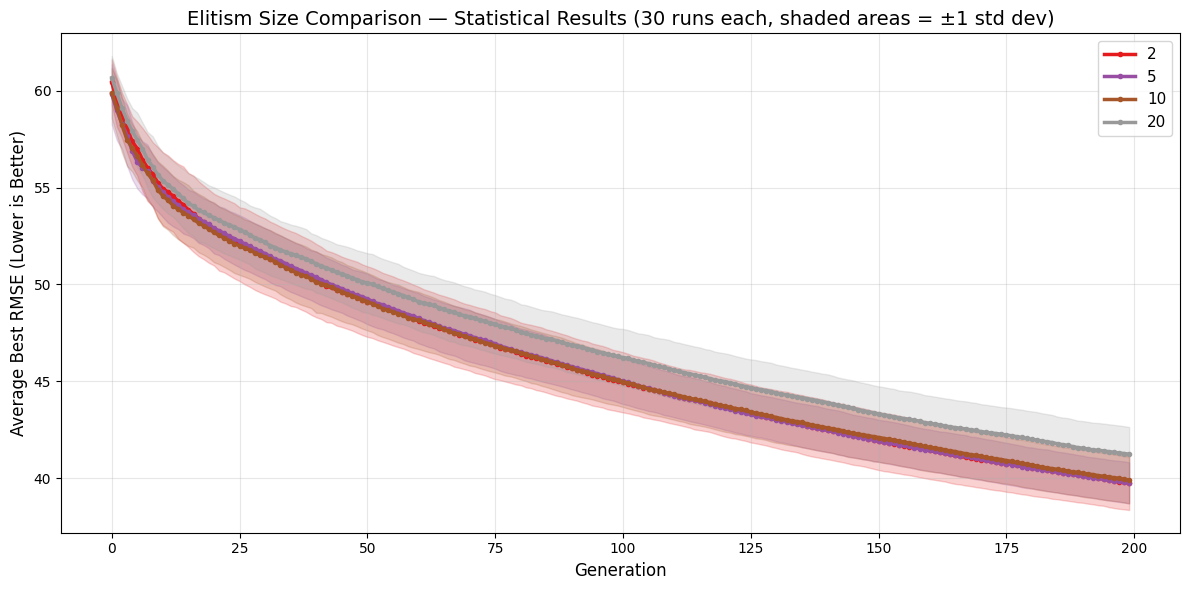

In [21]:
elitism_n = [
    "2",
    "5",
    "10",
    "20"
]

plot_statistical_comparison(
    elitism_n_statistical_comparison,
    labels=elitism_n,
    title="Elitism Size Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

## Find the best population size to use

this test is not fair, as the bigger the population, the more evaluations were done

but it may be useful to check which is the biggest population size that still makes sense to use while not being too slow

In [17]:
population_size_statistical_comparison = run_ga_statistical_comparison(
    "population_size",
    [
        200,
        400,
        800,
        1500
    ]
)


Starting statistical comparison: 120 GA runs, 24,000 total generations



Progress: 100%|██████████| 24000/24000 [6:07:31<00:00,  1.09 gen/s]  


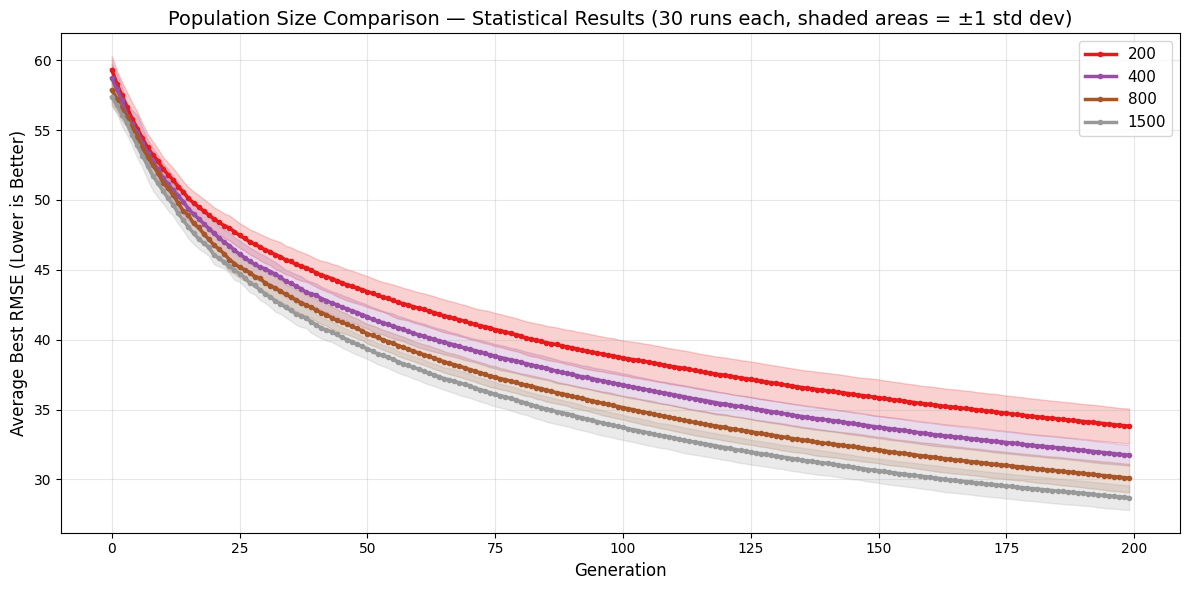

In [18]:
population_sizes = [
    "200",
    "400",
    "800",
    "1500"
]

plot_statistical_comparison(
    population_size_statistical_comparison,
    labels=population_sizes,
    title="Population Size Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [3]:
population_size_statistical_comparison = run_ga_statistical_comparison(
    "population_size",
    [
        200,
        400,
        800,
        1500
    ],
    eval_budget=96_000
)


Starting statistical comparison: 120 GA runs, 11,520,000 total evaluations



Progress:   1%|          | 108600/11520000 [02:40<4:41:10, 676.40 evaluation/s]


KeyboardInterrupt: 

<h2 id="chapter7" style="color:#89AC76;">7. Final GA run </h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>


In [19]:
best_sol, history, avg_history = genetic_algorithm(
    solution_class=TriangleSolution,
    population_size=800,
    n_generations=2000,
    selection_function=lambda p: tournament_selection(p, tournament_size=10),
    crossover_function=uniform_crossover,
    mutation_function=triangle_gaussian_mutation,
    crossover_rate=0.9,
    mutation_rate=0.01,
    mutation_rate_decay=None,
    elitism_n=2
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 58.2414 | avg RMSE: 68.5261 | mut rate: 0.01000
Gen   50 | best RMSE: 32.6811 | avg RMSE: 33.0376 | mut rate: 0.01000
Gen  100 | best RMSE: 28.4080 | avg RMSE: 28.5723 | mut rate: 0.01000
Gen  150 | best RMSE: 26.3321 | avg RMSE: 26.4435 | mut rate: 0.01000
Gen  200 | best RMSE: 25.0181 | avg RMSE: 25.1214 | mut rate: 0.01000
Gen  250 | best RMSE: 24.0273 | avg RMSE: 24.1036 | mut rate: 0.01000
Gen  300 | best RMSE: 23.2857 | avg RMSE: 23.3618 | mut rate: 0.01000
Gen  350 | best RMSE: 22.6252 | avg RMSE: 22.7005 | mut rate: 0.01000
Gen  400 | best RMSE: 22.1101 | avg RMSE: 22.1982 | mut rate: 0.01000
Gen  450 | best RMSE: 21.7268 | avg RMSE: 21.8015 | mut rate: 0.01000
Gen  500 | best RMSE: 21.3595 | avg RMSE: 21.4520 | mut rate: 0.01000
Gen  550 | best RMSE: 21.1173 | avg RMSE: 21.2031 | mut rate: 0.01000
Gen  600 | best RMSE: 20.7939 | avg RMSE: 20.8765 | mut rate: 0.01000
Gen  650 | best RMSE: 20.5164 | avg RMSE: 20.6087 | mut rate: 0.01000
Gen  700 | best RMSE

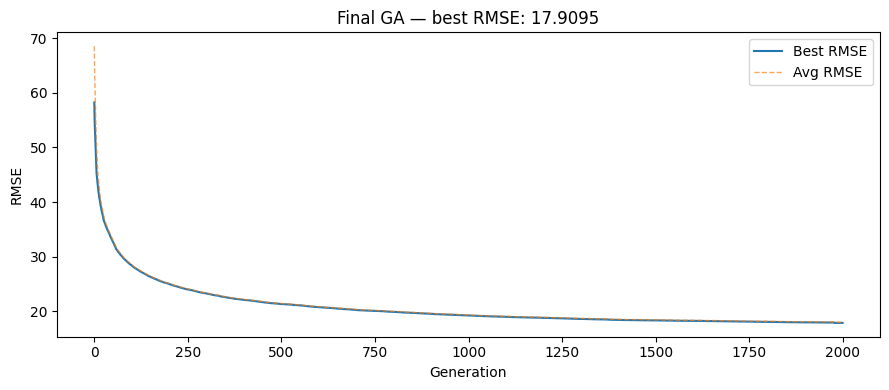

In [22]:
plot_fitness_history(
    history,
    avg_history,
    title=f"Final GA — best RMSE: {history[-1]:.4f}",
)

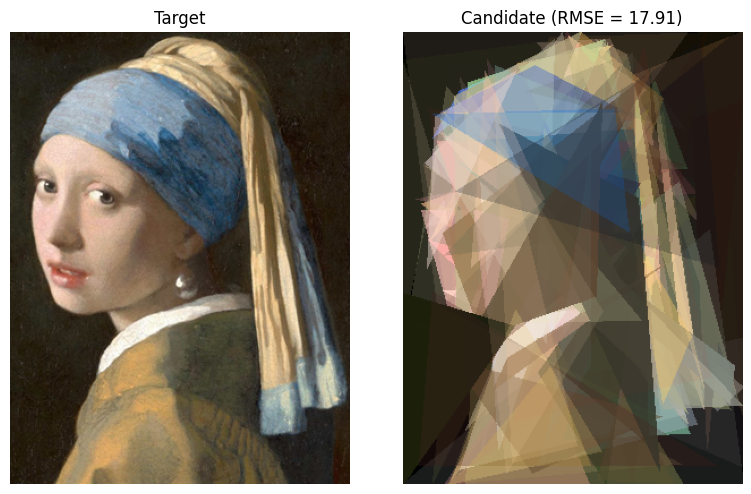

In [20]:
best_sol.show()

In [25]:
best_sol, history, avg_history = genetic_algorithm(
    solution_class=TriangleSolution,
    population_size=400,
    n_generations=1000,
    selection_function=AutomaticFitnessSharingSelection(
        sigma_share=80.0,   # Se a diversidade continuar baixa, aumenta para 80-100
        alpha=1.0,
        tournament_size=10
    ),
    crossover_function=uniform_crossover,
    mutation_function=triangle_gaussian_mutation,
    crossover_rate=0.9,
    mutation_rate=0.01,
    mutation_rate_decay=None,
    elitism_n=2
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 60.1562 | avg RMSE: 68.6287 | mut rate: 0.01000
Gen   50 | best RMSE: 34.7843 | avg RMSE: 35.0662 | mut rate: 0.01000
Gen  100 | best RMSE: 30.5220 | avg RMSE: 30.6616 | mut rate: 0.01000
Gen  150 | best RMSE: 28.4553 | avg RMSE: 28.5616 | mut rate: 0.01000
Gen  200 | best RMSE: 26.9714 | avg RMSE: 27.0516 | mut rate: 0.01000
Gen  250 | best RMSE: 25.8417 | avg RMSE: 25.9300 | mut rate: 0.01000
Gen  300 | best RMSE: 24.9865 | avg RMSE: 25.0911 | mut rate: 0.01000
Gen  350 | best RMSE: 24.4177 | avg RMSE: 24.4775 | mut rate: 0.01000
Gen  400 | best RMSE: 24.0039 | avg RMSE: 24.0680 | mut rate: 0.01000
Gen  450 | best RMSE: 23.7104 | avg RMSE: 23.7889 | mut rate: 0.01000
Gen  500 | best RMSE: 23.5171 | avg RMSE: 23.5894 | mut rate: 0.01000
Gen  550 | best RMSE: 23.2576 | avg RMSE: 23.3343 | mut rate: 0.01000
Gen  600 | best RMSE: 23.1049 | avg RMSE: 23.1722 | mut rate: 0.01000
Gen  650 | best RMSE: 22.8723 | avg RMSE: 22.9431 | mut rate: 0.01000
Gen  700 | best RMSE

In [26]:
np.random.seed(33)
best_sol, history, avg_history = genetic_algorithm(
    solution_class=TriangleSolution,
    population_size=400,
    n_generations=100,
    selection_function=AutomaticFitnessSharingSelection(
        sigma_share=80.0,   # Se a diversidade continuar baixa, aumenta para 80-100
        alpha=1.0,
        tournament_size=10
    ),
    crossover_function=uniform_crossover,
    mutation_function=triangle_gaussian_mutation,
    crossover_rate=0.9,
    mutation_rate=0.01,
    mutation_rate_decay=None,
    elitism_n=2
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 56.8508 | avg RMSE: 68.4456 | mut rate: 0.01000
Gen   50 | best RMSE: 33.7603 | avg RMSE: 34.0854 | mut rate: 0.01000
Gen   99 | best RMSE: 29.9674 | avg RMSE: 30.1884 | mut rate: 0.01000

Finished. Best RMSE: 29.9529
Best RMSE : 29.9529


In [29]:
np.random.seed(33)
best_sol, history, avg_history = genetic_algorithm(
    solution_class=TriangleSolution,
    population_size=400,
    n_generations=100,
    selection_function=lambda p: tournament_selection(p, tournament_size=10),
    crossover_function=uniform_crossover,
    mutation_function=triangle_gaussian_mutation,
    crossover_rate=0.9,
    mutation_rate=0.10,
    mutation_rate_decay=1e-2,
    elitism_n=2,
    verbose_every=25
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 56.8508 | avg RMSE: 68.4456 | mut rate: 0.10000
Gen   25 | best RMSE: 37.0697 | avg RMSE: 38.0170 | mut rate: 0.07798
Gen   50 | best RMSE: 31.5563 | avg RMSE: 32.0388 | mut rate: 0.06080
Gen   75 | best RMSE: 28.5261 | avg RMSE: 28.9262 | mut rate: 0.04741
Gen   99 | best RMSE: 27.1236 | avg RMSE: 27.4084 | mut rate: 0.03734

Finished. Best RMSE: 27.0792
Best RMSE : 27.0792


In [4]:
np.random.seed(33)
best_sol, history, avg_history = genetic_algorithm(
    solution_class=TriangleSolution,
    population_size=800,
    n_generations=2000,
    selection_function=lambda p: tournament_selection(p, tournament_size=10),
    crossover_function=geometric_crossover,
    mutation_function=triangle_gaussian_mutation,
    crossover_rate=0.9,
    mutation_rate=0.02,
    mutation_rate_decay=None,
    elitism_n=2,
    verbose_every=25
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 56.8070 | avg RMSE: 65.8000 | mut rate: 0.02000
Gen   25 | best RMSE: 46.4644 | avg RMSE: 46.9343 | mut rate: 0.02000
Gen   50 | best RMSE: 42.2371 | avg RMSE: 42.6454 | mut rate: 0.02000
Gen   75 | best RMSE: 39.3935 | avg RMSE: 39.6897 | mut rate: 0.02000
Gen  100 | best RMSE: 37.1126 | avg RMSE: 37.3414 | mut rate: 0.02000
Gen  125 | best RMSE: 35.2347 | avg RMSE: 35.4394 | mut rate: 0.02000
Gen  150 | best RMSE: 33.6371 | avg RMSE: 33.8060 | mut rate: 0.02000
Gen  175 | best RMSE: 32.5188 | avg RMSE: 32.6719 | mut rate: 0.02000
Gen  200 | best RMSE: 31.6487 | avg RMSE: 31.7877 | mut rate: 0.02000
Gen  225 | best RMSE: 30.9544 | avg RMSE: 31.0834 | mut rate: 0.02000
Gen  250 | best RMSE: 30.4192 | avg RMSE: 30.5337 | mut rate: 0.02000
Gen  275 | best RMSE: 29.9835 | avg RMSE: 30.1026 | mut rate: 0.02000
Gen  300 | best RMSE: 29.5818 | avg RMSE: 29.6948 | mut rate: 0.02000
Gen  325 | best RMSE: 29.1979 | avg RMSE: 29.3030 | mut rate: 0.02000
Gen  350 | best RMSE

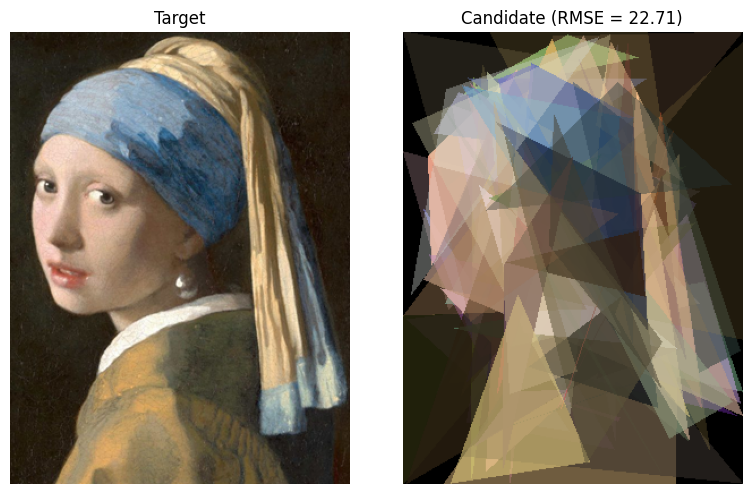

In [5]:
best_sol.show()

In [7]:
best_sol, history, avg_history = genetic_algorithm(
    solution_class=AdaptiveMutationRateTriangleSolution,
    population_size=200,
    n_generations=5000,
    selection_function=lambda p: tournament_selection(p, tournament_size=10),
    crossover_function=uniform_crossover,
    mutation_function=lambda i, m: triangle_gaussian_mutation(i, m, sigma_mutation_rate=0.01),
    crossover_rate=0.9,
    mutation_rate=0.,
    mutation_rate_decay=None,
    elitism_n=2
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 57.3479 | avg RMSE: 63.3593 | mut rate: 0.01213
Gen   50 | best RMSE: 36.0273 | avg RMSE: 36.4001 | mut rate: 0.04569
Gen  100 | best RMSE: 30.7105 | avg RMSE: 31.1697 | mut rate: 0.05259
Gen  150 | best RMSE: 28.3687 | avg RMSE: 28.6696 | mut rate: 0.04814
Gen  200 | best RMSE: 26.9950 | avg RMSE: 27.1978 | mut rate: 0.03401
Gen  250 | best RMSE: 26.1195 | avg RMSE: 26.2354 | mut rate: 0.01966
Gen  300 | best RMSE: 25.7203 | avg RMSE: 25.8456 | mut rate: 0.01910
Gen  350 | best RMSE: 25.3267 | avg RMSE: 25.4467 | mut rate: 0.01868
Gen  400 | best RMSE: 25.0357 | avg RMSE: 25.1479 | mut rate: 0.01625
Gen  450 | best RMSE: 24.7617 | avg RMSE: 24.8641 | mut rate: 0.01645
Gen  500 | best RMSE: 24.5981 | avg RMSE: 24.6810 | mut rate: 0.01587
Gen  550 | best RMSE: 24.4898 | avg RMSE: 24.5969 | mut rate: 0.01491
Gen  600 | best RMSE: 24.3363 | avg RMSE: 24.4554 | mut rate: 0.01684
Gen  650 | best RMSE: 24.2091 | avg RMSE: 24.3084 | mut rate: 0.01597
Gen  700 | best RMSE

KeyboardInterrupt: 

<h2 id="chapter4" style="color:#89AC76;">8. Save Best Result </h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>


In [21]:
out_path = "best_result.png"
best_sol.get_image().save(out_path)
print(f"Saved best candidate to: {out_path}")

Saved best candidate to: best_result.png


<span style="color:#BA8E23;">

### <h2><strong>CONFIRM IF IS DONE - UPDATE MAIN</strong></h2>
1. **Hybrid GA + Local Search (Hill Climbing or CMA-ES) - ANDRÉ** - CONFIRMAR SE ESTÁ
	- ran Hill Climbing as a local search after the GA converged, using the GA's best solution as the starting point.

**Afonso** - Passar tudo para o main.


### <h2><strong>MEDIUM PRIORITY</strong></h2>
1. **Smarter initialization** - **Cláudio**
- Sample triangle colours from target pixels
- Cuts early RMSE immediately

### <h2><strong>ANALYSIS AND REPORTING </strong></h2>
1. **Wilcoxon statistical tests with a tournament structure**<br>
Use Wilcoxon signed-rank tests to determine which configuration was statistically significantly better, then ran a tournament-style elimination comparing the winner sequentially against challengers.

mas adaptadoa rmse

2. **Search space size**
Frame as continuous space
Show problem awareness

(as it continuous)


</span>